# Mushroom Model Final Training

Run `2-Models-Tuning.ipynb` first. This notebook loads its best-parameter pickle, fits and evaluates the final stacking classifier, selects a poisonous-class threshold from validation data, and saves the fitted estimator.


First we are gonna import all the needed librarys etc

In [9]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

after that we are gonna load our data and make the necesary changes after analysing.

In [10]:
# Load the CSV saved in the parent mushrooms folder.
dataset_path = Path('../mushroom_project_dataset.csv')
df = pd.read_csv(dataset_path)

# Remove noise / sparse columns identified during data analysis; ignore missing names safely.
df = df.drop(columns=['jumbled_noise_0', 'jumbled_noise_1', 'spore-print-color'], errors='ignore')
if 'class' not in df.columns:
    raise ValueError("Dataset must contain a 'class' target column.")

X = df.drop(columns='class')
y = df['class'].astype(str)
class_labels = sorted(y.unique())
if len(class_labels) != 2:
    raise ValueError(f'Expected a binary mushroom target, found classes: {class_labels}')

# Stratified 70/20/10 split: reserve test first, then split the other 90%.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=2/9, random_state=42, stratify=y_train_val
)
print(f'Train: {len(X_train)} rows ({len(X_train) / len(X):.0%})')
print(f'Validation: {len(X_val)} rows ({len(X_val) / len(X):.0%})')
print(f'Test: {len(X_test)} rows ({len(X_test) / len(X):.0%})')
print('Class labels:', class_labels)

# Fit imputation and encoding only inside training folds via model pipelines.
numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessing = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])
categorical_preprocessing = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_preprocessing, numeric_columns),
    ('categorical', categorical_preprocessing, categorical_columns),
])

Train: 3500 rows (70%)
Validation: 1000 rows (20%)
Test: 500 rows (10%)
Class labels: ['e', 'p']


The final model in this notebook is a stacking classifier. It combines decision tree, random forest, gradient boosting, and XGBoost base estimators.

## Train, validate, and export the stacking model

Estimator settings are loaded from `models/best_model_parameters.pkl` and applied unchanged to the four base estimators used inside the stacking classifier. Only the final stacking model is fitted and exported. The validation set selects a poisonous-class probability threshold; the held-out test set is used only for final comparison. Pickles should only be loaded from sources you trust.


Loaded tuned parameters from: C:\school\AI\Deep Learning\Cloud_AI\CloudAI-Challenge\mushrooms\Cisse\models\best_model_parameters.pkl
Validation metrics (e = edible, p = poisonous):


,accuracy,edible_precision,edible_recall,poisonous_recall
stacking,0.765,0.811,0.810,0.691


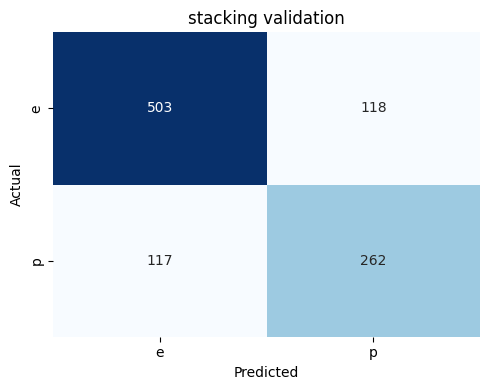

Held-out test metrics (e = edible, p = poisonous):


,accuracy,edible_precision,edible_recall,poisonous_recall
stacking,0.792,0.837,0.826,0.735


Accuracy by model (validation and held-out test):
          validation_accuracy  test_accuracy
stacking                0.765          0.792
Saved 1 fitted model pickle files and model outputs to: C:\school\AI\Deep Learning\Cloud_AI\CloudAI-Challenge\mushrooms\Cisse\models


In [11]:
# Load hyperparameters produced by 2-Models-Tuning.ipynb.
output_dir = Path('models')
parameter_path = output_dir / 'best_model_parameters.pkl'
if not parameter_path.exists():
    raise FileNotFoundError(
        f'{parameter_path} not found. Run 2-Models-Tuning.ipynb first to create the parameter pickle.'
    )
with parameter_path.open('rb') as parameter_file:
    tuning_results = pickle.load(parameter_file)
if tuning_results.get('format_version') != 1:
    raise ValueError('Unsupported or invalid model parameter pickle format.')
required_models = {'decision_tree', 'random_forest', 'gradient_boosting', 'xgboost'}
if set(tuning_results.get('best_params', {})) != required_models:
    raise ValueError('The tuning pickle must contain parameters for all four base models.')
if tuning_results.get('feature_columns') != X.columns.tolist():
    raise ValueError('Tuning parameters were generated for a different feature set.')
best_params = tuning_results['best_params']
print('Loaded tuned parameters from:', parameter_path.resolve())

# Define each base estimator. Pipelines keep preprocessing attached to the fitted model.
base_estimators = {
    'decision_tree': DecisionTreeClassifier(
        max_depth=15, min_samples_leaf=2, class_weight='balanced', random_state=42
    ),
    'random_forest': RandomForestClassifier(
        n_estimators=100, max_depth=None, min_samples_split=5, min_samples_leaf=1,
        class_weight='balanced', n_jobs=-1, random_state=42, max_features='sqrt'
    ),
    'gradient_boosting': GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42
    ),
    'xgboost': XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric='logloss', n_jobs=-1, random_state=42
    ),
}

base_models = {
    name: Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', estimator),
    ])
    for name, estimator in base_estimators.items()
}

for name, model in base_models.items():
    model.set_params(**best_params[name])

stacking_estimators = [
    (name, clone(model)) for name, model in base_models.items()
]
models = {
    'stacking': StackingClassifier(
        estimators=stacking_estimators,
        final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced'),
        cv=5,
        n_jobs=-1,
    )
}

# Target mapping for XGBoost compatibility: Map 'e' -> 0, 'p' -> 1
label_map = {label: idx for idx, label in enumerate(class_labels)}
y_train_encoded = np.array([label_map[val] for val in y_train])
y_val_encoded = np.array([label_map[val] for val in y_val])
y_test_encoded = np.array([label_map[val] for val in y_test])
encoded_labels = [label_map[label] for label in class_labels]

# Fit the final stacking model and calculate validation metrics.
validation_metrics = {}
validation_predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train_encoded)
    predictions = model.predict(X_val)
    validation_predictions[name] = predictions
    
    # Generate classification report mapped back to original class names ('e', 'p')
    report = classification_report(
        y_val_encoded, predictions, labels=encoded_labels, 
        target_names=class_labels, output_dict=True, zero_division=0
    )
    
    validation_metrics[name] = {
        'accuracy': accuracy_score(y_val_encoded, predictions),
        'classification_report': report,
        'confusion_matrix': confusion_matrix(y_val_encoded, predictions, labels=encoded_labels),
    }

validation_summary = pd.DataFrame({
    name: {
        'accuracy': metrics['accuracy'],
        'edible_precision': metrics['classification_report'].get('e', {}).get('precision', np.nan),
        'edible_recall': metrics['classification_report'].get('e', {}).get('recall', np.nan),
        'poisonous_recall': metrics['classification_report'].get('p', {}).get('recall', np.nan),
    }
    for name, metrics in validation_metrics.items()
}).T.sort_values('accuracy', ascending=False)

print('Validation metrics (e = edible, p = poisonous):')
display(validation_summary.style.format('{:.3f}'))

fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4))
if len(models) == 1:
    axes = [axes]

for ax, (name, metrics) in zip(axes, validation_metrics.items()):
    sns.heatmap(
        metrics['confusion_matrix'], annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=class_labels, yticklabels=class_labels, ax=ax,
    )
    ax.set(title=f'{name.replace("_", " ")} validation', xlabel='Predicted', ylabel='Actual')
plt.tight_layout()
plt.show()

# Final held-out test comparison; do not use these results to tune or choose cutoffs.
test_metrics = {}
test_predictions = {}
for name, model in models.items():
    predictions = model.predict(X_test)
    test_predictions[name] = predictions
    
    report = classification_report(
        y_test_encoded, predictions, labels=encoded_labels, 
        target_names=class_labels, output_dict=True, zero_division=0
    )
    
    test_metrics[name] = {
        'accuracy': accuracy_score(y_test_encoded, predictions),
        'classification_report': report,
        'confusion_matrix': confusion_matrix(y_test_encoded, predictions, labels=encoded_labels),
    }

test_summary = pd.DataFrame({
    name: {
        'accuracy': metrics['accuracy'],
        'edible_precision': metrics['classification_report'].get('e', {}).get('precision', np.nan),
        'edible_recall': metrics['classification_report'].get('e', {}).get('recall', np.nan),
        'poisonous_recall': metrics['classification_report'].get('p', {}).get('recall', np.nan),
    }
    for name, metrics in test_metrics.items()
}).T.sort_values('accuracy', ascending=False)

print('Held-out test metrics (e = edible, p = poisonous):')
display(test_summary.style.format('{:.3f}'))

# Print accuracy for every individual model and the stacking model.
accuracy_summary = pd.DataFrame({
    'validation_accuracy': {
        name: metrics['accuracy'] for name, metrics in validation_metrics.items()
    },
    'test_accuracy': {
        name: metrics['accuracy'] for name, metrics in test_metrics.items()
    },
}).sort_values('test_accuracy', ascending=False)

print('Accuracy by model (validation and held-out test):')
print(accuracy_summary.to_string(float_format=lambda value: f'{value:.3f}'))

# Save each fitted estimator, plus a complete bundle with split metrics and predictions.
output_dir = Path('models')
output_dir.mkdir(parents=True, exist_ok=True)
for name, model in models.items():
    with (output_dir / f'{name}.pkl').open('wb') as model_file:
        pickle.dump(model, model_file, protocol=pickle.HIGHEST_PROTOCOL)

model_outputs = {
    'class_labels': class_labels,
    'label_map': label_map,
    'feature_columns': X.columns.tolist(),
    'best_params': best_params,
    'best_cv_scores': tuning_results['best_cv_scores'],
    'validation_metrics': validation_metrics,
    'test_metrics': test_metrics,
    'validation_predictions': validation_predictions,
    'test_predictions': test_predictions,
}
with (output_dir / 'mushroom_model_outputs.pkl').open('wb') as outputs_file:
    pickle.dump(model_outputs, outputs_file, protocol=pickle.HIGHEST_PROTOCOL)

print(f'Saved {len(models)} fitted model pickle files and model outputs to: {output_dir.resolve()}')

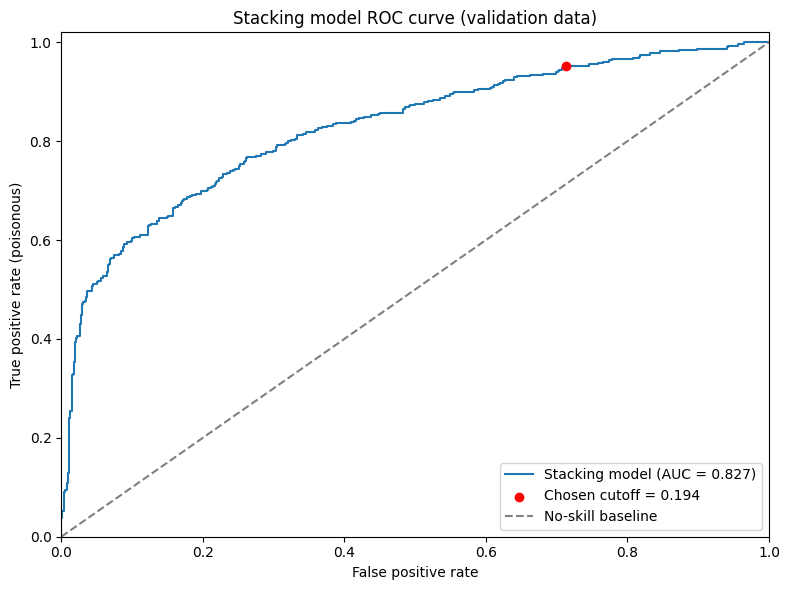

Validation ROC AUC: 0.827
Chosen poisonous probability threshold: 0.194
Target validation poisonous recall: 95.0%
Validation false-positive rate at cutoff: 0.713
Validation poisonous recall at cutoff: 0.953


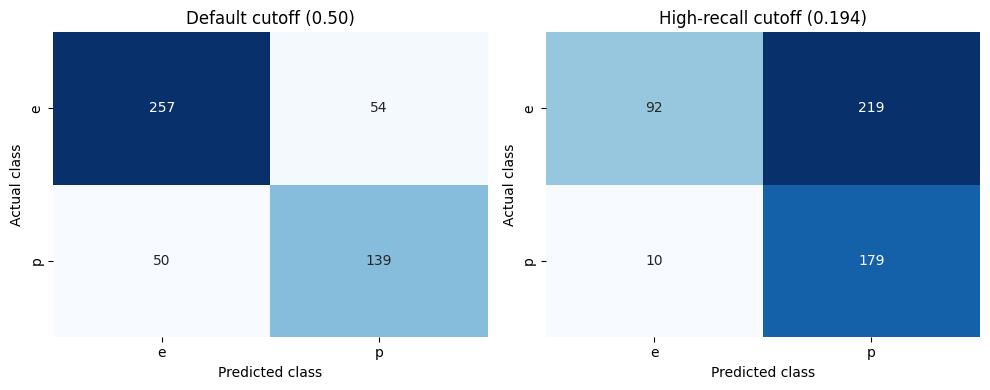

Confusion matrix rows = actual [e, p], columns = predicted [e, p].
False negatives (poisonous mushrooms predicted edible):
  Default cutoff: 50
  High-recall cutoff: 10
False positives (edible mushrooms predicted poisonous; these may increase):
  Default cutoff: 54
  High-recall cutoff: 219
Poisonous recall on test set:
  Default cutoff: 0.735
  High-recall cutoff: 0.947
Updated model outputs at: C:\school\AI\Deep Learning\Cloud_AI\CloudAI-Challenge\mushrooms\Cisse\models\mushroom_model_outputs.pkl


In [12]:
# Plot the stacking model's validation ROC and select a high-poisonous-recall cutoff.
from sklearn.metrics import auc, roc_curve

poisonous_label = label_map['p']
model = models['stacking']
poisonous_column = list(model.classes_).index(poisonous_label)
validation_probabilities = model.predict_proba(X_val)[:, poisonous_column]
fpr, tpr, candidates = roc_curve(y_val_encoded == poisonous_label, validation_probabilities)
model_auc = auc(fpr, tpr)

# Require at least 95% poisonous recall on validation; choose the highest qualifying cutoff.
target_poisonous_recall = 0.95
qualifying_indices = np.flatnonzero((tpr >= target_poisonous_recall) & np.isfinite(candidates))
if qualifying_indices.size == 0:
    raise ValueError(
        f'No finite threshold reaches {target_poisonous_recall:.0%} poisonous recall on validation data.'
    )
best_index = int(qualifying_indices[np.argmax(candidates[qualifying_indices])])
poisonous_threshold = float(candidates[best_index])

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, label=f'Stacking model (AUC = {model_auc:.3f})')
ax.scatter(fpr[best_index], tpr[best_index], color='red', zorder=3,
           label=f'Chosen cutoff = {poisonous_threshold:.3f}')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='No-skill baseline')
ax.set(xlabel='False positive rate', ylabel='True positive rate (poisonous)',
       title='Stacking model ROC curve (validation data)', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f'Validation ROC AUC: {model_auc:.3f}')
print(f'Chosen poisonous probability threshold: {poisonous_threshold:.3f}')
print(f'Target validation poisonous recall: {target_poisonous_recall:.1%}')
print(f'Validation false-positive rate at cutoff: {fpr[best_index]:.3f}')
print(f'Validation poisonous recall at cutoff: {tpr[best_index]:.3f}')

# Compare the default 0.50 cutoff with the recall-focused validation cutoff on test data.
test_probabilities = model.predict_proba(X_test)[:, poisonous_column]
default_test_predictions = np.where(test_probabilities >= 0.50, poisonous_label, label_map['e'])
threshold_test_predictions = np.where(
    test_probabilities >= poisonous_threshold, poisonous_label, label_map['e']
)
default_test_confusion = confusion_matrix(
    y_test_encoded, default_test_predictions, labels=encoded_labels
)
threshold_test_confusion = confusion_matrix(
    y_test_encoded, threshold_test_predictions, labels=encoded_labels
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, matrix, title in zip(
    axes,
    [default_test_confusion, threshold_test_confusion],
    ['Default cutoff (0.50)', f'High-recall cutoff ({poisonous_threshold:.3f})'],
):
    sns.heatmap(
        matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=class_labels, yticklabels=class_labels, ax=ax,
    )
    ax.set(title=title, xlabel='Predicted class', ylabel='Actual class')
plt.tight_layout()
plt.show()

print('Confusion matrix rows = actual [e, p], columns = predicted [e, p].')
print('False negatives (poisonous mushrooms predicted edible):')
print(f'  Default cutoff: {default_test_confusion[1, 0]}')
print(f'  High-recall cutoff: {threshold_test_confusion[1, 0]}')
print('False positives (edible mushrooms predicted poisonous; these may increase):')
print(f'  Default cutoff: {default_test_confusion[0, 1]}')
print(f'  High-recall cutoff: {threshold_test_confusion[0, 1]}')
print('Poisonous recall on test set:')
print(f'  Default cutoff: {default_test_confusion[1, 1] / default_test_confusion[1].sum():.3f}')
print(f'  High-recall cutoff: {threshold_test_confusion[1, 1] / threshold_test_confusion[1].sum():.3f}')

model_outputs['poisonous_probability_threshold'] = poisonous_threshold
model_outputs['validation_roc'] = {
    'fpr': fpr,
    'tpr': tpr,
    'auc': model_auc,
    'threshold': poisonous_threshold,
    'target_poisonous_recall': target_poisonous_recall,
}
model_outputs['test_default_confusion_matrix'] = default_test_confusion
model_outputs['test_threshold_confusion_matrix'] = threshold_test_confusion
model_outputs['test_threshold_predictions'] = threshold_test_predictions
with (output_dir / 'mushroom_model_outputs.pkl').open('wb') as outputs_file:
    pickle.dump(model_outputs, outputs_file, protocol=pickle.HIGHEST_PROTOCOL)
print('Updated model outputs at:', (output_dir / 'mushroom_model_outputs.pkl').resolve())